# Roll-angle limit examples

The two worked examples from the field-rotation note,
[docs/field_rotation_rate/README.md](../field_rotation_rate/README.md):

1. Maximum roll offsets for ε Eridani when CPGS fixes the sky PA at mid-visit (README section 4).
2. Fixed-PA observations of HIP 71618 (README section 5).

The README has the derivation, the guideline formulas and tables, and the assumptions and limitations (section 7).
The calculations use `tools/plan_roll_limits.py` and `roman_pointing` with the solar ephemeris. Target names are
resolved with `get_target_coords` (CORGIDB, then SIMBAD), so the notebook needs network access.

PA_V3 is the position angle of the observatory +Z body axis (V3), the body vector normal to the sunshield. It is
equivalent to PA_Z, as returned by `getRomanPositionAngle`. For EXCAM, PA_APER ≈ PA_V3 + 150°.

![EXCAM orientation at nominal roll and with a +10° roll offset](excam_roll_geometry.png)

**Figure.** Sky and observatory axes in the EXCAM data frame (X_EXCAM right, Y_EXCAM up) for a target (star) at the
nominal roll angle (left) and with a +10° roll offset (right).

* **Viewing direction.** In an EXCAM data frame, the line of sight to the sky goes into the page.
* **Observatory axes.** For any roll angle, the orientations of the observatory vectors Y_OBS and Z_OBS (V2 and V3 in
  Science Center terminology) remain fixed in EXCAM. Only the sky (N, E) turns with roll.
* **Field orientation.** We can define the EXCAM field orientation by PA_V3, the position angle of Z_OBS (V3) measured
  counterclockwise from celestial north. In this example PA_V3 ≅ 120° at nominal roll. PA_APER, the PA of Y_EXCAM, is
  −90°, so PA_APER ≈ PA_V3 + 150°.
* **SIAF angle.** V3IdlYAngle ≅ −30° for aperture `CGI_CEN` is measured from V3 to the CGI line-of-sight Y axis
  (CGI LOS_Y), which points along −Y_EXCAM. The 150° offset therefore corresponds to V3IdlYAngle + 180°.
* **Roll offset.** A positive roll offset (`applyRollAngle` sense) causes the sky scene to rotate counterclockwise in
  the EXCAM data frame. This decreases the position angle of Z_OBS (V3): the +10° offset on the right lowers both
  PA_V3 and PA_APER by 10°, to ≅ 110° and −100°.

In [1]:
import os
import sys
import tempfile

from IPython.display import Image, display

# run from docs/Notebooks: make the repository's src/ and tools/ importable
repo = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
sys.path[:0] = [os.path.join(repo, "src"), os.path.join(repo, "tools")]
script = os.path.join(repo, "tools", "plan_roll_limits.py")

from plan_roll_limits import EXAMPLE, plot_target_roll_limits, resolve_target

## Example 1: maximum roll offsets for ε Eridani

### The problem

The observer requests a start date and two roll offsets, A_nom and B_nom. One visit contains several repetitions of
both rolls, in alternating sequence. Roll offsets follow the `roman_pointing` convention: a roll of +A_nom passed to
`applyRollAngle` changes PA_V3 (and PA_APER) by −A_nom. CPGS converts each requested roll into an absolute sky PA
computed for the planned middle of the visit:

$$ P_A = \mathrm{PA_{nom}}(t_\mathrm{mid}) - A_\mathrm{nom}, \qquad P_B = \mathrm{PA_{nom}}(t_\mathrm{mid}) - B_\mathrm{nom} $$

The spacecraft then holds that PA. The nominal PA keeps rotating, so the roll actually needed at execution time t is

$$ A(t) = A_\mathrm{nom} + \big[\mathrm{PA_{nom}}(t) - \mathrm{PA_{nom}}(t_\mathrm{mid})\big] $$

That needed roll must stay within ±15° over the whole interval in which the visit might execute:

* **The visit itself** reaches D/2 on either side of mid-visit, where D is the visit duration.
* **Any start shift** the schedulers may need adds U days on top of that, for example within a 3 day scheduling buffer.

To first order, with H = D/2 + U the farthest the visit can execute from the planned mid-visit:

$$ |A_\mathrm{nom}|,\ |B_\mathrm{nom}| \;\le\; 15^\circ - |\mathrm{rate}| \times \left(\tfrac{D}{2} + U\right) $$

### Constraints

* Target: ε Eridani, resolved by name with `--target "eps Eri"` (found in CORGIDB): RA 53.228°, Dec −9.458°
  (β = −27.7°).
* Visit duration D = 1.5 days (conservative), planned to start 2027-01-19 00:00 UTC, so CPGS sets the sky PA for the
  planned mid-visit at 2027-01-19 18:00 UTC.
* The start may move up to 3 days early or late (U = 3 days, H = D/2 + U = 3.75 days). The visit can therefore start
  anywhere in the Jan 16–22 scheduling window (Jan 16 00:00 to Jan 22 00:00 UTC) and may end as late as Jan 23 12:00.
* Over that span the Sun angle is 103.5°–110.2° and PA_V3 increases at ≈ 0.52°/day.

### Allowed roll offsets

The calculator evaluates the constraints with `roman_pointing` and the solar ephemeris. This is the same as
`PYTHONPATH=src python tools/plan_roll_limits.py --target "eps Eri" --start 2027-01-19T00:00:00 --duration 1.5 --early 3 --late 3`
from the repository root.

In [2]:
%run $script --target "eps Eri" --start 2027-01-19T00:00:00 --duration 1.5 --early 3 --late 3

  Found 'eps Eri' in CORGIDB (StarAliases lookup).
Target eps Eri: RA 53.2284 deg, Dec -9.4582 deg (ICRS, J2000)
Target beta = -27.71 deg, Sun angle 103.5-110.2 deg, dPA_V3/dt at mid-visit = +0.517 deg/day
Allowed requested roll offsets (applyRollAngle sense): -13.02 to +13.10 deg; symmetric limit +/-13.02 deg
Reachable fixed sky PA_V3 over the span: 232.15 to 258.27 deg; maximum-separation pair 232.15 and 258.27 deg (separation 26.12 deg)


The last line is the fixed-PA result of Example 2 (README section 5).

### Reading the plot

The figure is the README's `roll_limits_example.png`. `EXAMPLE` in `tools/plan_roll_limits.py` holds the visit
parameters above and the illustrative rolls A and B at ±13°.

  Found 'eps Eri' in CORGIDB (StarAliases lookup).
Target eps Eri: RA 53.2284 deg, Dec -9.4582 deg (ICRS, J2000)


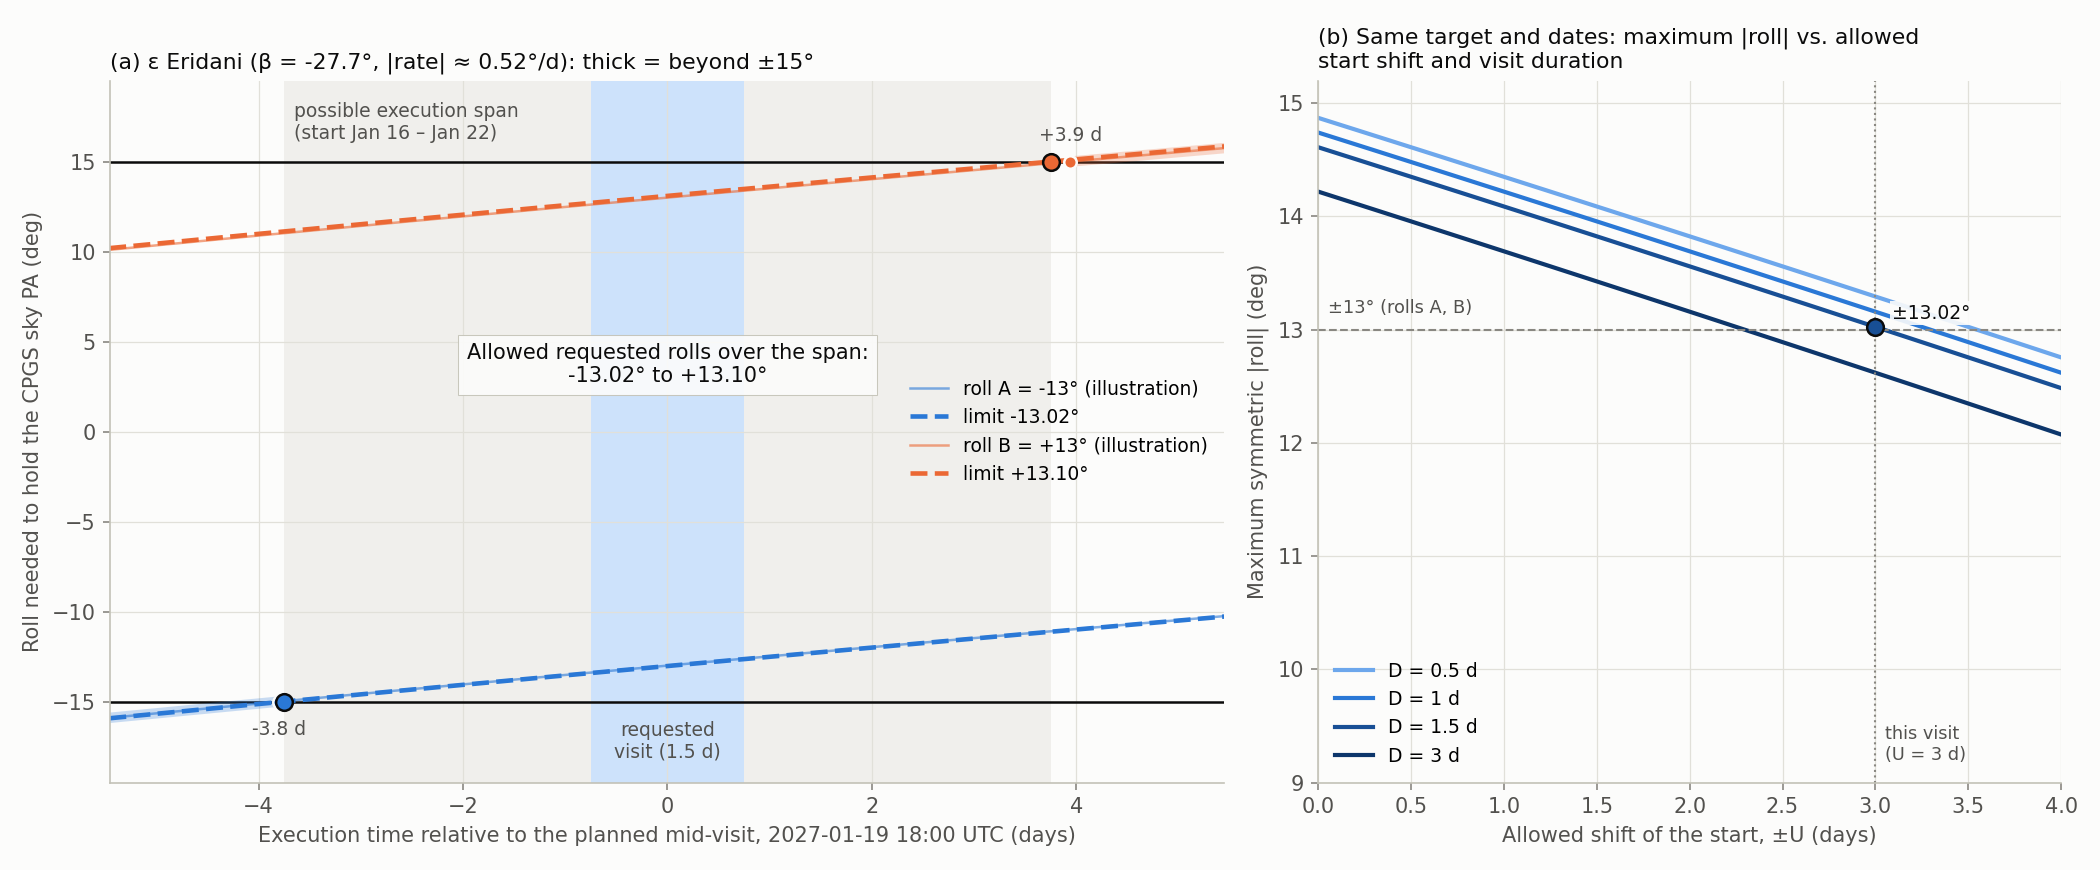

In [3]:
example = dict(EXAMPLE)
example["ra"], example["dec"] = resolve_target(example.pop("target"))
with tempfile.TemporaryDirectory() as outdir:
    plot_target_roll_limits(outdir, **example)
    display(Image(os.path.join(outdir, example["filename"])))

* **Panel (a)** plots the roll needed to hold the CPGS sky PA against the actual execution time. A requested roll is
  allowed only if its line stays within ±15° across the whole possible execution span (gray band).
  * The lines slope upward because PA_V3 increases for β < 0.
  * The dashed lines are the limiting rolls. The −13.02° roll reaches −15° at the start of the span (earliest start),
    and the +13.10° roll reaches +15° at its end (latest end). So the negative roll is limited by running early, and
    the positive roll by running late.
  * The thin lines at ±13° (rolls A and B) are an illustration. They lie just inside the limits, reaching ±15° at
    3.8 days before and 3.9 days after mid-visit, just outside the 3.75-day span.
* **Panel (b)** shows the symmetric limit vs. allowed start shift U for several visit durations. D = 1.5 days with
  U = 3 days gives ±13.02°. Each extra day of U costs about 0.52° of roll, and each extra day of D about 0.26°.
* **One-sided shift.** If the start can only slip later (`--early 0 --late 3`), the negative roll is limited only by
  the visit length, and the allowed range widens to −14.61° to +13.10°:

In [4]:
%run $script --target "eps Eri" --start 2027-01-19T00:00:00 --duration 1.5 --early 0 --late 3

  Found 'eps Eri' in CORGIDB (StarAliases lookup).
Target eps Eri: RA 53.2284 deg, Dec -9.4582 deg (ICRS, J2000)
Target beta = -27.71 deg, Sun angle 103.5-107.5 deg, dPA_V3/dt at mid-visit = +0.517 deg/day
Allowed requested roll offsets (applyRollAngle sense): -14.61 to +13.10 deg; symmetric limit +/-13.10 deg
Reachable fixed sky PA_V3 over the span: 232.15 to 259.86 deg; maximum-separation pair 232.15 and 259.86 deg (separation 27.71 deg)


## Example 2: fixed-PA observations of HIP 71618

Here the observer specifies two exact sky position angles, PA_1 and PA_2 (in PA_V3), instead of roll offsets. One visit
contains several repetitions of both PAs, in alternating sequence. At each execution time the roll is set so that PA_V3
lands exactly on the requested value. PAs here are PA_V3; for EXCAM, PA_APER ≈ PA_V3 + 150°.

### Reachable PAs and the maximum-separation pair

A roll r gives PA_V3 = PA_nom(t) − r, so an exact sky PA P needs the roll r(t) = PA_nom(t) − P. Over the possible
execution span of the visit (earliest start to latest end, of length T = D + early shift + late shift), P is reachable
throughout only if

$$ \max_t \mathrm{PA_{nom}}(t) - 15^\circ \;\le\; P \;\le\; \min_t \mathrm{PA_{nom}}(t) + 15^\circ . $$

Both PA_1 and PA_2 must lie in this interval. Its two ends are the pair of PAs with the largest separation:

$$ \big|\mathrm{PA_2} - \mathrm{PA_1}\big|_\mathrm{max} = 2\times 15^\circ - \Delta\mathrm{PA}(T), $$

where ΔPA(T) ≈ |rate| × T is the nominal PA swing over the span. If ΔPA(T) > 30°, no single fixed PA is reachable for
the whole span. This is the result of Example 1 in absolute terms: the interval ends are PA_nom(t_mid) − a_max and
PA_nom(t_mid) − a_min, where a_min and a_max are the allowed roll offsets.

### Constraints

`tools/plan_roll_limits.py` prints the reachable interval with the roll limits. With `--pa PA1 PA2` it also checks two
requested PAs and gives the roll each one needs over the span.

* Target: resolved by name with `--target` (from SIMBAD; it is not in CORGIDB), RA 219.709°, Dec +44.405°
  (β = +55.4°, in the continuous viewing zone).
* Visit duration D = 5 days, in the Apr 19–27, 2027 schedule window (Apr 19 00:00 to Apr 27 00:00 UTC).
* Centering the visit in the window allows a start shift of (8 − 5)/2 = 1.5 days, rounded up to 2 days early and late.
  The planned start is 2027-04-20 12:00 UTC and the planned mid-visit 2027-04-23 00:00 UTC. The possible execution
  span is 9 days, Apr 18 12:00 to Apr 27 12:00.
* Over that span the Sun angle is 121.7°–123.5°, near the anti-Sun edge of the FOR, so PA_V3 rotates quickly
  (≈ 1.13°/day).

### Reachable PAs

Same as `PYTHONPATH=src python tools/plan_roll_limits.py --target "HIP 71618" --start 2027-04-20T12:00:00 --duration 5 --early 2 --late 2 --pa 5 20`
from the repository root:

In [5]:
%run $script --target "HIP 71618" --start 2027-04-20T12:00:00 --duration 5 --early 2 --late 2 --pa 5 20

  'HIP 71618' not found in CORGIDB — querying SIMBAD...
Target HIP 71618: RA 219.7093 deg, Dec +44.4045 deg (ICRS, J2000)
Target beta = 55.44 deg, Sun angle 121.7-123.5 deg, dPA_V3/dt at mid-visit = -1.133 deg/day
Allowed requested roll offsets (applyRollAngle sense): -9.96 to +9.85 deg; symmetric limit +/-9.85 deg
Reachable fixed sky PA_V3 over the span: 1.36 to 21.17 deg; maximum-separation pair 1.36 and 21.17 deg (separation 19.81 deg)
PA1 = 5.00 deg: needed roll +1.17 to +11.36 deg over the span (reachable)
PA2 = 20.00 deg: needed roll -13.83 to -3.64 deg over the span (reachable)


Over the 9-day span PA_V3 swings by 10.2°, so the two PAs can be at most 19.8° apart: 1.36° and 21.17°. Any pair inside
that interval, such as 5° and 20°, is reachable throughout. Applying the needed rolls with `applyRollAngle` holds both
limiting PAs with |roll| ≤ 15° over the whole span.